# Vẽ đường hồi quy tìm được bằng công thức (mục 3.3) và dự đoán trên tập kiểm tra

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

Tập huấn luyện: chiều cao (cm) và cân nặng (kg) của 13 người

In [2]:
X = np.array([[147, 150, 153, 158, 163, 165, 168, 170,
               173, 175, 178, 180, 183]]).T
y = np.array([49, 50, 51, 54, 58, 59, 60, 62, 63, 64, 66, 67, 68])

w = (Xbar^T Xbar)^+ Xbar^T y

In [3]:
Xbar = np.concatenate((np.ones((X.shape[0], 1)), X), axis=1)
w_0, w_1 = np.linalg.pinv(Xbar.T @ Xbar) @ Xbar.T @ y

Tập kiểm tra: 2 người cao 155 cm và 160 cm

-33.735410206299385 0.5592049619426046 [52.94135889 55.7373837 ]


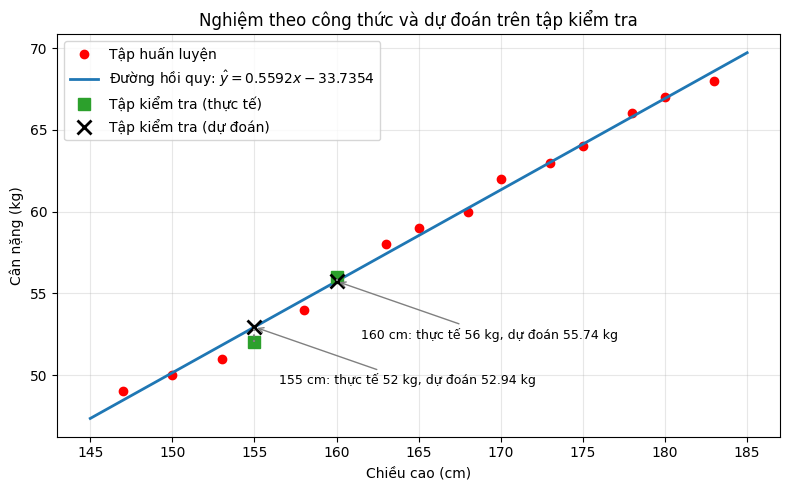

In [4]:
x_test = np.array([155, 160])
y_test = np.array([52, 56])            # cân nặng thực tế
y_pred = w_0 + w_1 * x_test            # cân nặng dự đoán

x_line = np.linspace(145, 185, 2)      # hai đầu mút để vẽ đường hồi quy
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(X, y, 'ro', label="Tập huấn luyện")
ax.plot(x_line, w_0 + w_1 * x_line, color="#1F77B4", lw=2,
        label=rf"Đường hồi quy: $\hat{{y}} = {w_1:.4f}x {w_0:+.4f}$")
ax.plot(x_test, y_test, 's', color="#2CA02C", ms=8, label="Tập kiểm tra (thực tế)")
ax.plot(x_test, y_pred, 'x', color="black", ms=10, mew=2, label="Tập kiểm tra (dự đoán)")
for height, actual, predicted in zip(x_test, y_test, y_pred):
    # đoạn chấm nối giá trị thực tế và dự đoán thể hiện sai số
    ax.vlines(height, min(actual, predicted), max(actual, predicted), color="gray", ls=":")
    ax.annotate(f"{height} cm: thực tế {actual} kg, dự đoán {predicted:.2f} kg",
                xy=(height, predicted), xytext=(height + 1.5, predicted - 3.5), fontsize=9,
                arrowprops=dict(arrowstyle="->", color="gray"))

ax.set_xlabel("Chiều cao (cm)"); ax.set_ylabel("Cân nặng (kg)")
ax.set_title("Nghiệm theo công thức và dự đoán trên tập kiểm tra")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "normal_equation_fit.png", dpi=150)
print(w_0, w_1, y_pred)